# Solid–gas transition from ASE thermochemistry

Any `ase.thermochemistry` object can become a landau phase through `AsePhase`.

We use a carbon-like element with made-up parameters:

- **α**: a stiff harmonic crystal with the lowest energy at 0 K
- **β**: a softer harmonic crystal, higher in energy but with more vibrational entropy
- **gas**: a monatomic ideal gas

landau then finds the stable phase and the transition temperatures.

Saves `Solid_Gas_ASE.svg` and `.png`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from ase import Atoms
from ase.thermochemistry import HarmonicThermo, IdealGasThermo

import landau as ld
from landau.calculate import calc_phase_diagram
from landau.plot import plot_1d_T_phase_diagram

warnings.simplefilter("ignore")

OUT = "Solid_Gas_ASE.svg"

FIGSIZE = (6.4, 4.8)
FONTSIZE = 13
DPI = 200

## Phases from ASE

In [2]:
def crystal(name, vib_energy, energy):
    """Einstein crystal with three modes per atom at `vib_energy` (eV)."""
    thermo = HarmonicThermo(vib_energies=[vib_energy] * 3, potentialenergy=energy)
    return ld.AsePhase(name, fixed_concentration=0.0, thermochem=thermo)


alpha = crystal("α", vib_energy=0.15, energy=-7.40)
beta = crystal("β", vib_energy=0.10, energy=-7.25)

gas = ld.AsePhase(
    "gas",
    fixed_concentration=0.0,
    thermochem=IdealGasThermo(
        vib_energies=[], geometry="monatomic", atoms=Atoms("C"),
        symmetrynumber=1, spin=1, potentialenergy=0.0,
    ),
)

## Phase diagram

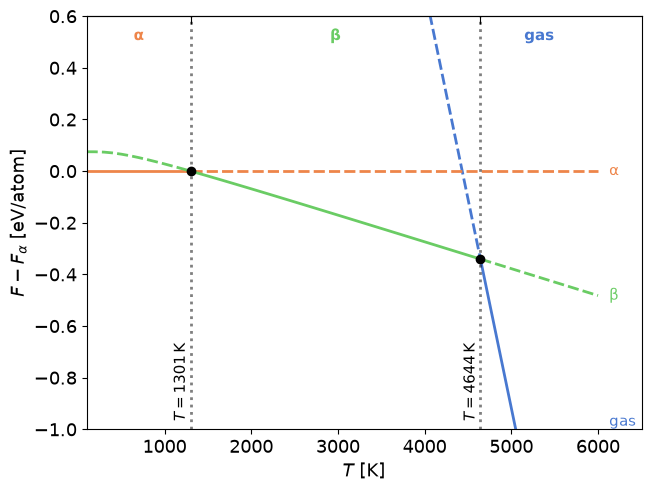

In [3]:
df = calc_phase_diagram([alpha, beta, gas], Ts=np.linspace(100, 6000, 60), mu=0.0, keep_unstable=True)

plt.style.use("default")
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
with plt.rc_context({"lines.linewidth": 2}):
    plot_1d_T_phase_diagram(df, ax=ax, reference_phase="α", ylim=(-1, 0.6))
ax.set_xlabel("$T$ [K]")
ax.set_ylabel(r"$F - F_\alpha$ [eV/atom]")

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)